# 02 — Entraînement des baselines classiques

Nous entraînons une référence majoritaire et des classifieurs TF-IDF avec régression logistique, puis nous sauvegardons modèles, prédictions, métriques et figures. Contributions partielles à **L04, L07 et L12**, et supports de résultats pour **L11**.

Le réglage par défaut est **`full`** : tout le train est utilisé pour apprendre, tout le dev pour calculer les scores. Un contrôle technique `smoke` de 100 exemples par partition précède le full ; ses résultats ne sont pas ceux affichés à la fin. Aucun apprentissage ou score sur le test officiel.

Prérequis : environnement du projet déjà installé (`docs/20_environnement_python.md`), sources locales autorisées et noyau **TuniScope (notebooks)** avec Matplotlib (`requirements-visualization.txt`, `docs/34_graphiques_validation.md`). Aucun téléchargement automatique.


In [1]:
from pathlib import Path
import importlib.util
import json
import os
import sys

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'scripts/project_uv.sh').is_file()), None)
if ROOT is None:
    raise RuntimeError('Ouvrir le notebook depuis le dépôt ou son dossier notebooks/.')
sys.path.insert(0, str(ROOT / 'scripts'))
from notebook_support import (
    CONFIGS, run_project, train_baselines, select_training_run,
    training_summary, export_training_figures,
)

# full : contrôle préalable puis apprentissage complet. smoke : petit contrôle seul.
# off : contrôle fictif uniquement, utilisé par les vérifications sans corpus.
TRAINING_MODE = os.environ.get('TUNISCOPE_BASELINE_MODE', 'full')
FAMILY = os.environ.get('TUNISCOPE_BASELINE_FAMILY', 'characters')
if TRAINING_MODE not in {'off', 'smoke', 'full'} or FAMILY not in CONFIGS:
    raise ValueError('Choisir off/smoke/full et characters/words/combined')
if TRAINING_MODE != 'off' and importlib.util.find_spec('matplotlib') is None:
    raise RuntimeError('Matplotlib manque dans ce noyau. Choisir TuniScope (notebooks) ; voir docs/34_graphiques_validation.md.')
check = json.loads(run_project('check_environment.py', capture=True))
assert check['corpus_read'] is False
print('Environnement : Python', check['python'], '|', check['device'].upper())
print('Représentation :', FAMILY)
print('Mode choisi :', TRAINING_MODE.upper())
if 'TUNISCOPE_BASELINE_MODE' in os.environ:
    print('Mode imposé par la variable TUNISCOPE_BASELINE_MODE.')
if TRAINING_MODE != 'full':
    print('ATTENTION : cette exécution ne produira pas un entraînement complet.')


Environnement : Python 3.12.15 | CPU
Représentation : characters
Mode choisi : FULL


## Apprentissage

1. Charger les partitions **v2** et vérifier les sources et la séparation des groupes.
2. Construire TF-IDF uniquement sur le train : caractères 3–5, mots 1–2 ou combinaison des deux, selon `FAMILY`.
3. Ajuster la régression logistique sur train. Comparer majorité, TF-IDF brut et TF-IDF normalisé pour chaque tâche, soit six résultats.
4. Prédire les labels du dev sans y apprendre les paramètres, calculer les métriques et sauvegarder les fichiers dans un nouveau dossier.
5. Recharger et vérifier les modèles. En mode `full`, sélectionner explicitement ce full pour le tableau final et les figures ; ne jamais reprendre le smoke en cas d'échec.

Effectifs du full : **TSAC 10 053 train / 1 774 dev** ; **MADAR 6 388 train / 800 dev**. Le contrôle préalable utilise 100 lignes par partition et ne remplace pas cette expérience complète.


In [2]:
runs = []
final_run = None
if TRAINING_MODE == 'off':
    print('Apprentissage désactivé ; contrôle fictif uniquement.')
else:
    runs = train_baselines(FAMILY, TRAINING_MODE, concise=True)
    final_run = select_training_run(runs, TRAINING_MODE)
    print()
    print(training_summary(final_run))


Contrôle préalable (smoke, 100 exemples par partition)…
Contrôle préalable réussi.
Entraînement complet (full, tout le train ; évaluation sur tout le dev)…
Entraînement complet et rechargement vérifiés.

ENTRAÎNEMENT COMPLET — FULL
Scores sur validation (dev), pas sur le test officiel.
Corpus  Système            Texte            Train     Dev    Accuracy    Macro-F1
TSAC    majority           brut             10053    1774    0.522548    0.343206
TSAC    tfidf_char         brut             10053    1774    0.928974    0.928898
TSAC    tfidf_char         normalisé        10053    1774    0.928974    0.928893
MADAR   majority           brut              6388     800    0.500000    0.222222
MADAR   tfidf_char         brut              6388     800    0.951250    0.949244
MADAR   tfidf_char         normalisé         6388     800    0.951250    0.949244

Modèles et résultats : /Users/elghoth/Desktop/NLP Project/outputs/baselines/notebooks/9bd620d96d3842b19e256879c8fdd674_characters_full


## Résultats

Nous produisons six PNG depuis **le run qui vient d'être entraîné et vérifié**, sans choisir un ancien dossier. Les JSON restent conservés pour les valeurs exactes et la traçabilité.

Les images et `summary.json` sont enregistrés dans le sous-dossier **`figures/` du run sélectionné**. Une réexécution de l'export utilise un nouveau nom si ce sous-dossier existe déjà. Les fichiers et les images restent sous `outputs/`, ignoré par Git.


In [3]:
figure_report = None
if final_run is not None:
    figure_report = export_training_figures(final_run)
    print('Mode des résultats :', figure_report['mode'].upper())
    print('Dossier des modèles et JSON :', ROOT / final_run['directory'])
    print('Dossier des PNG :', figure_report['directory'])
    print('Images enregistrées :', len(figure_report['images']))


Verified full run: six results, aligned validation IDs, model reloads, metrics recalculated
Mode des résultats : FULL
Dossier des modèles et JSON : /Users/elghoth/Desktop/NLP Project/outputs/baselines/notebooks/9bd620d96d3842b19e256879c8fdd674_characters_full
Dossier des PNG : /Users/elghoth/Desktop/NLP Project/outputs/baselines/notebooks/9bd620d96d3842b19e256879c8fdd674_characters_full/figures
Images enregistrées : 6


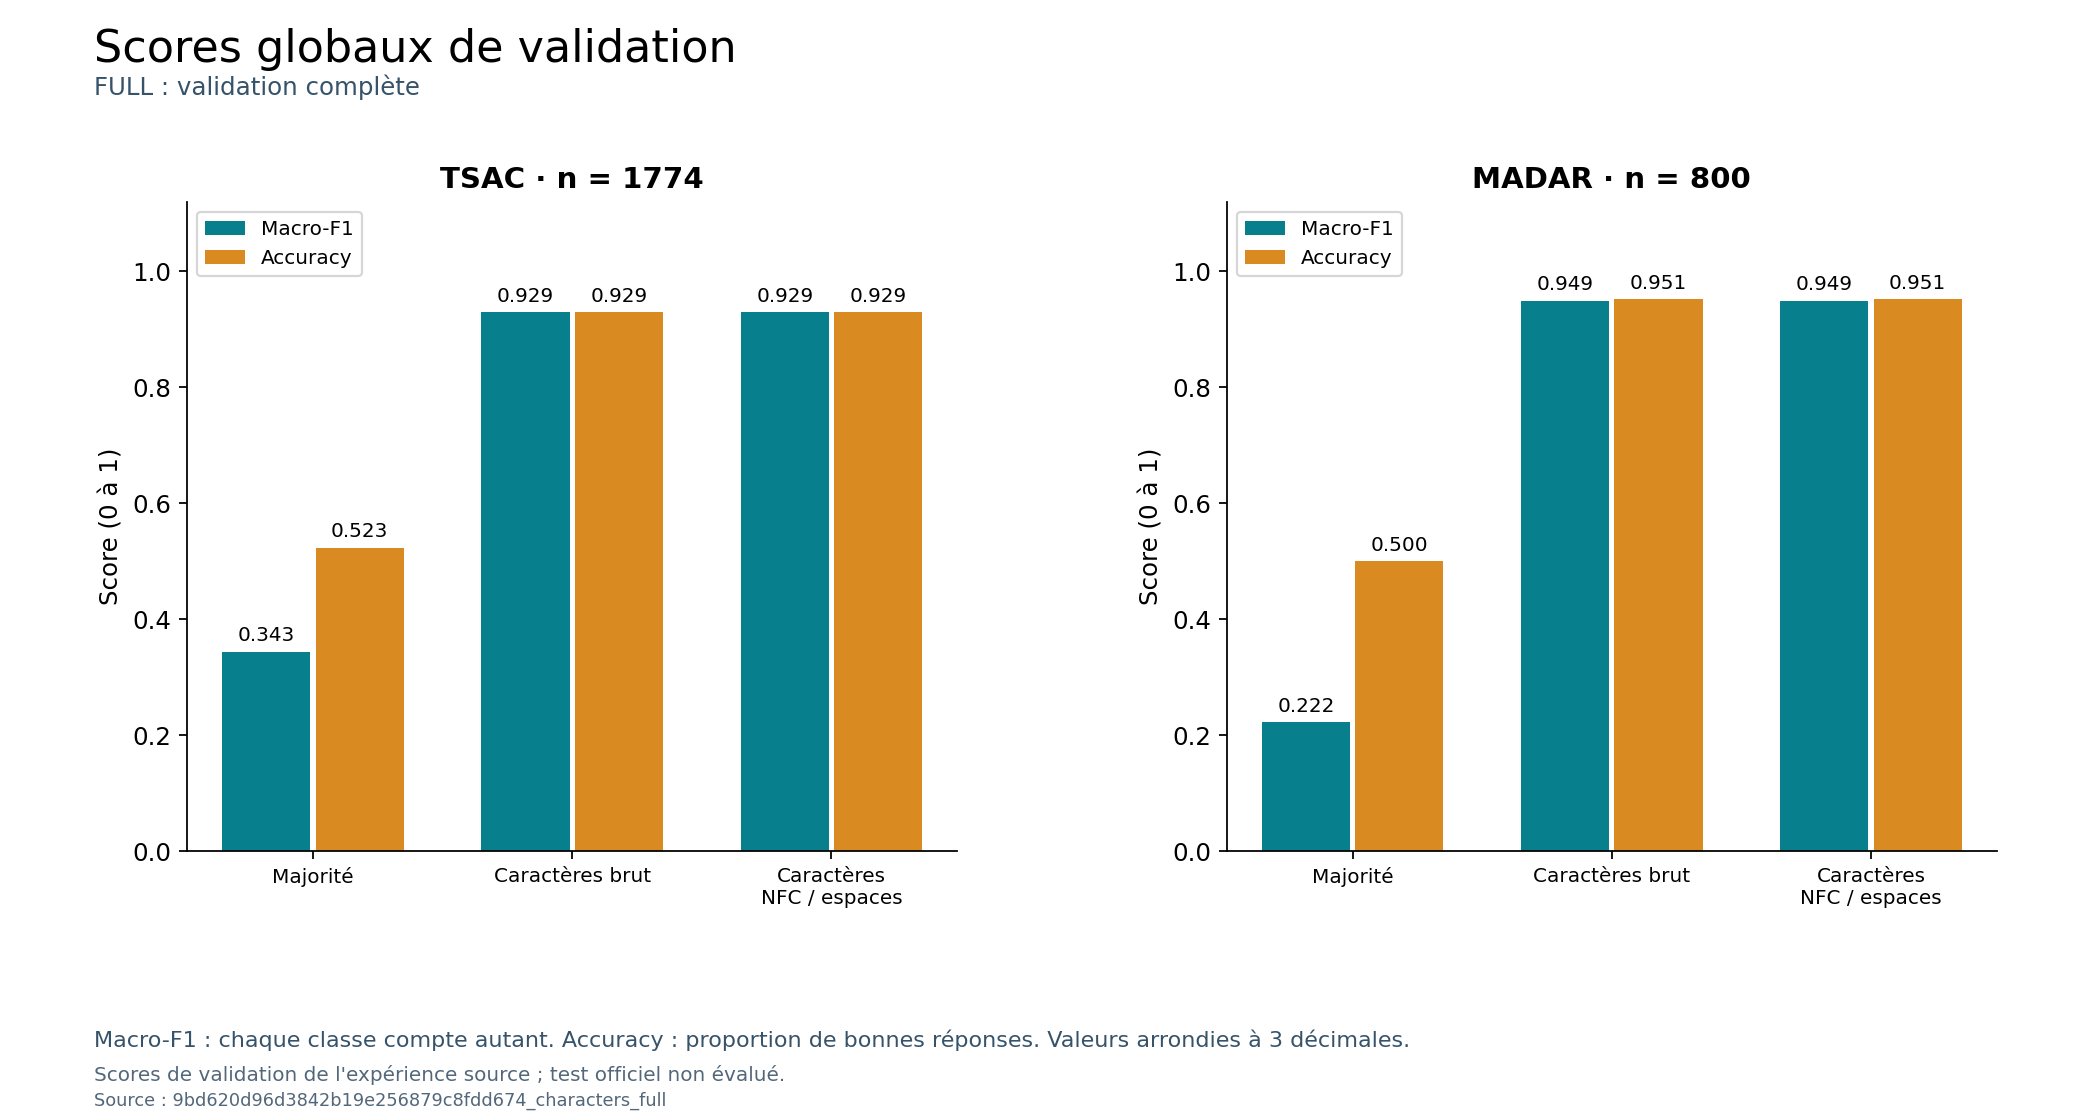

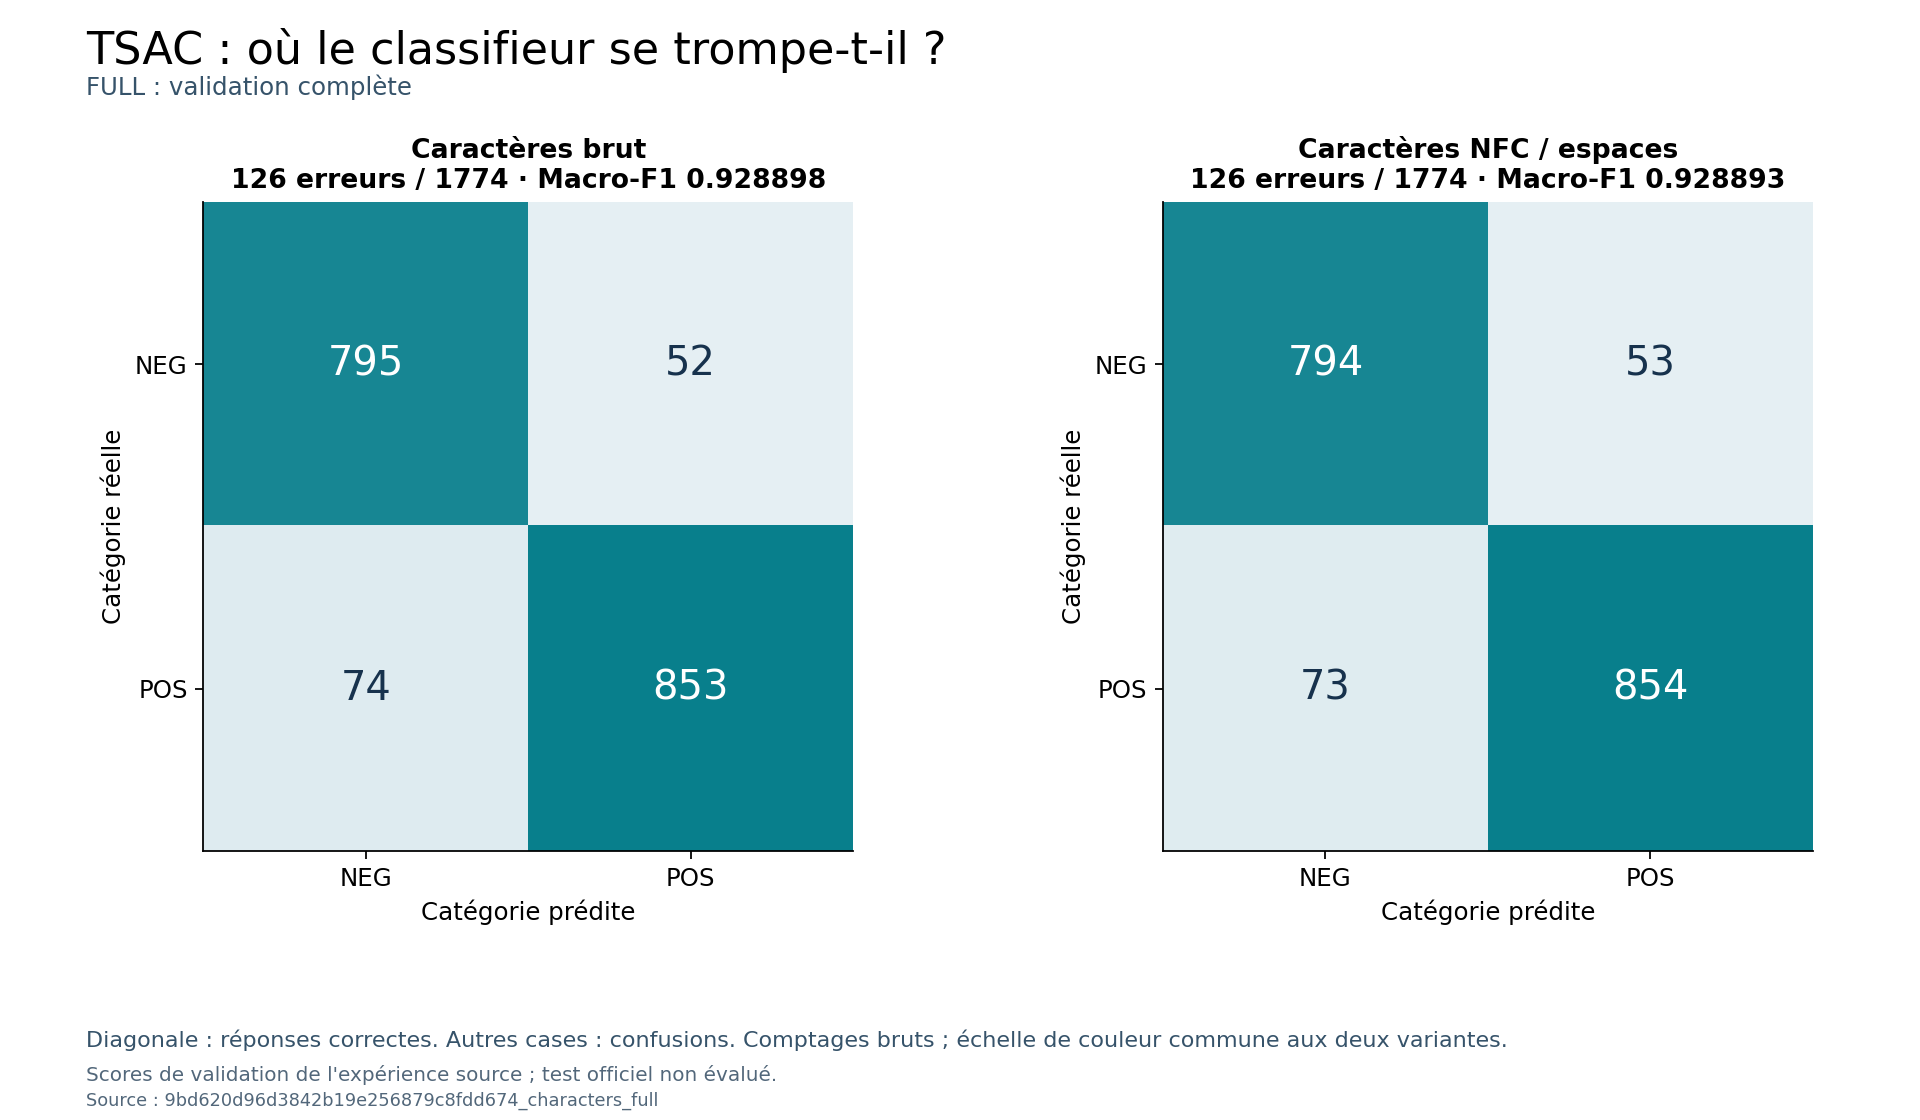

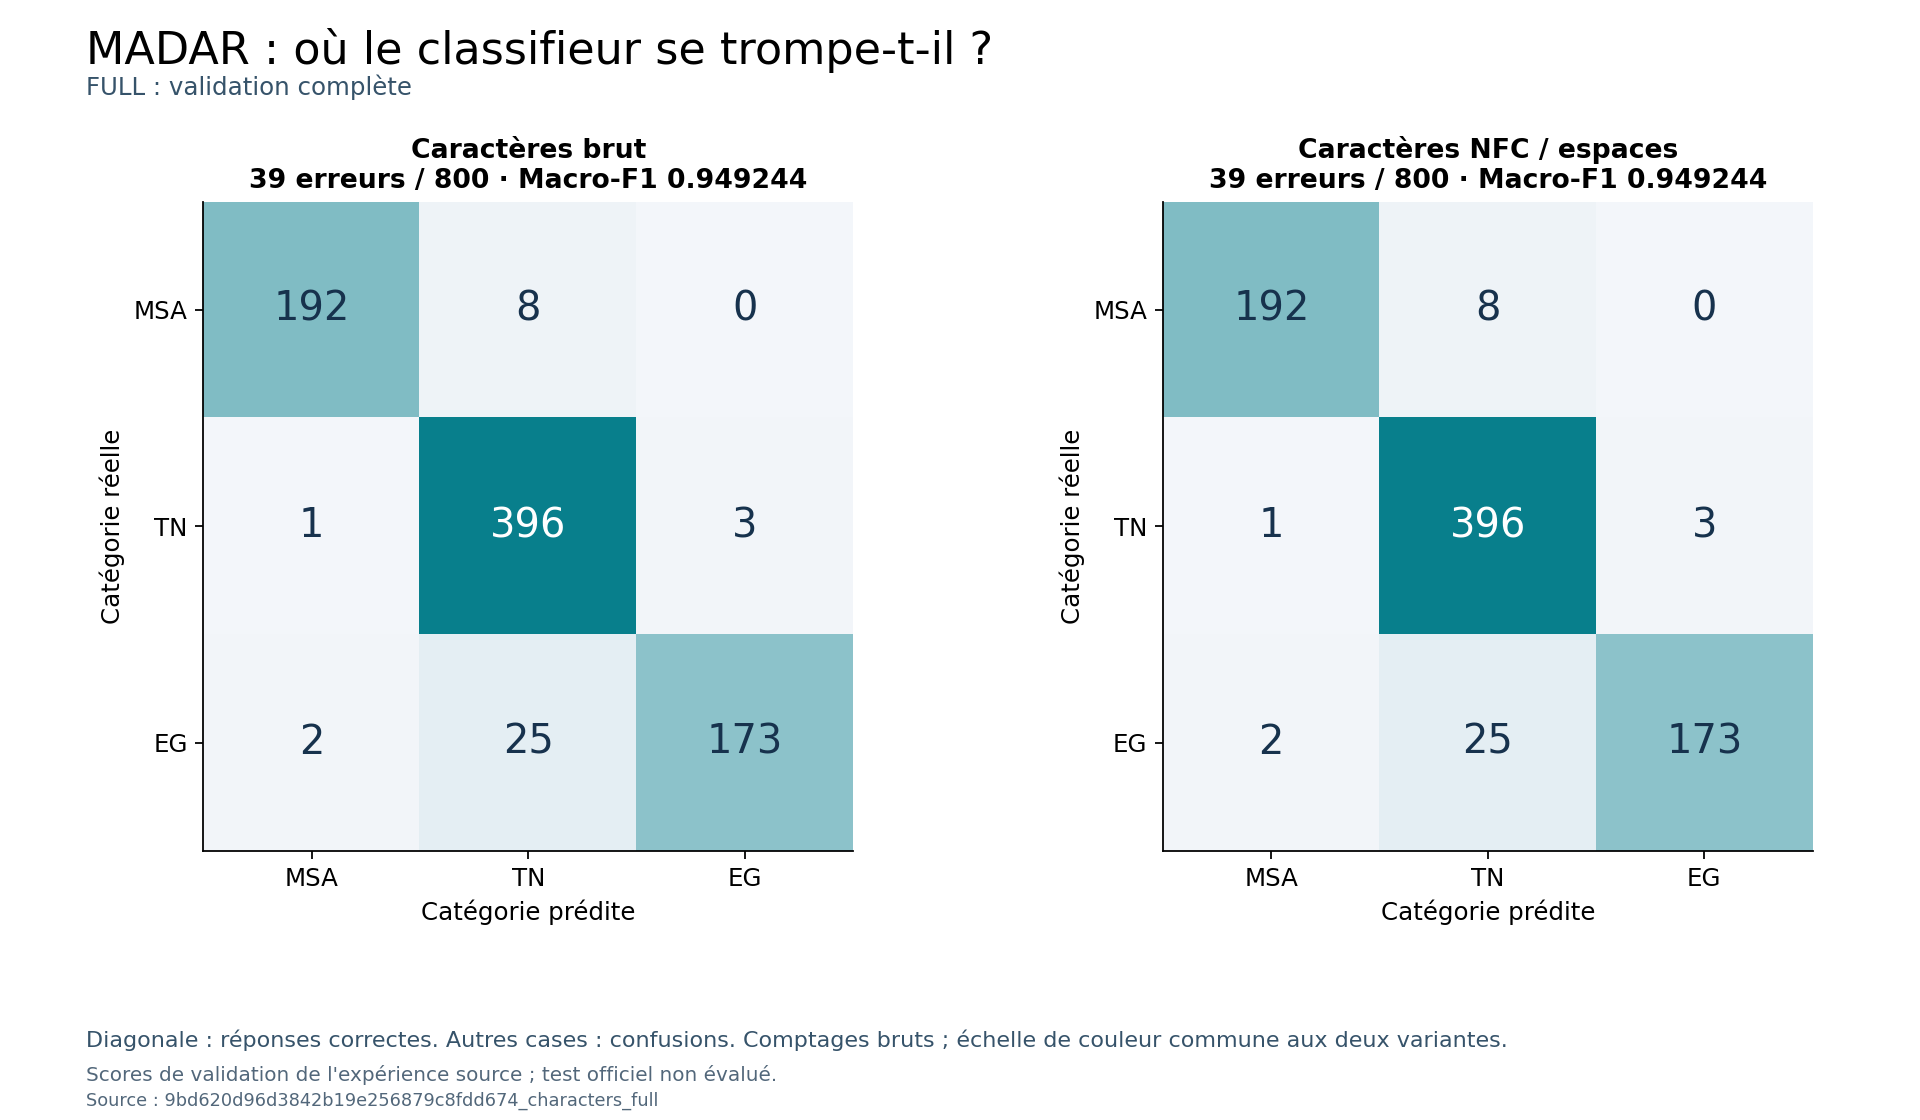

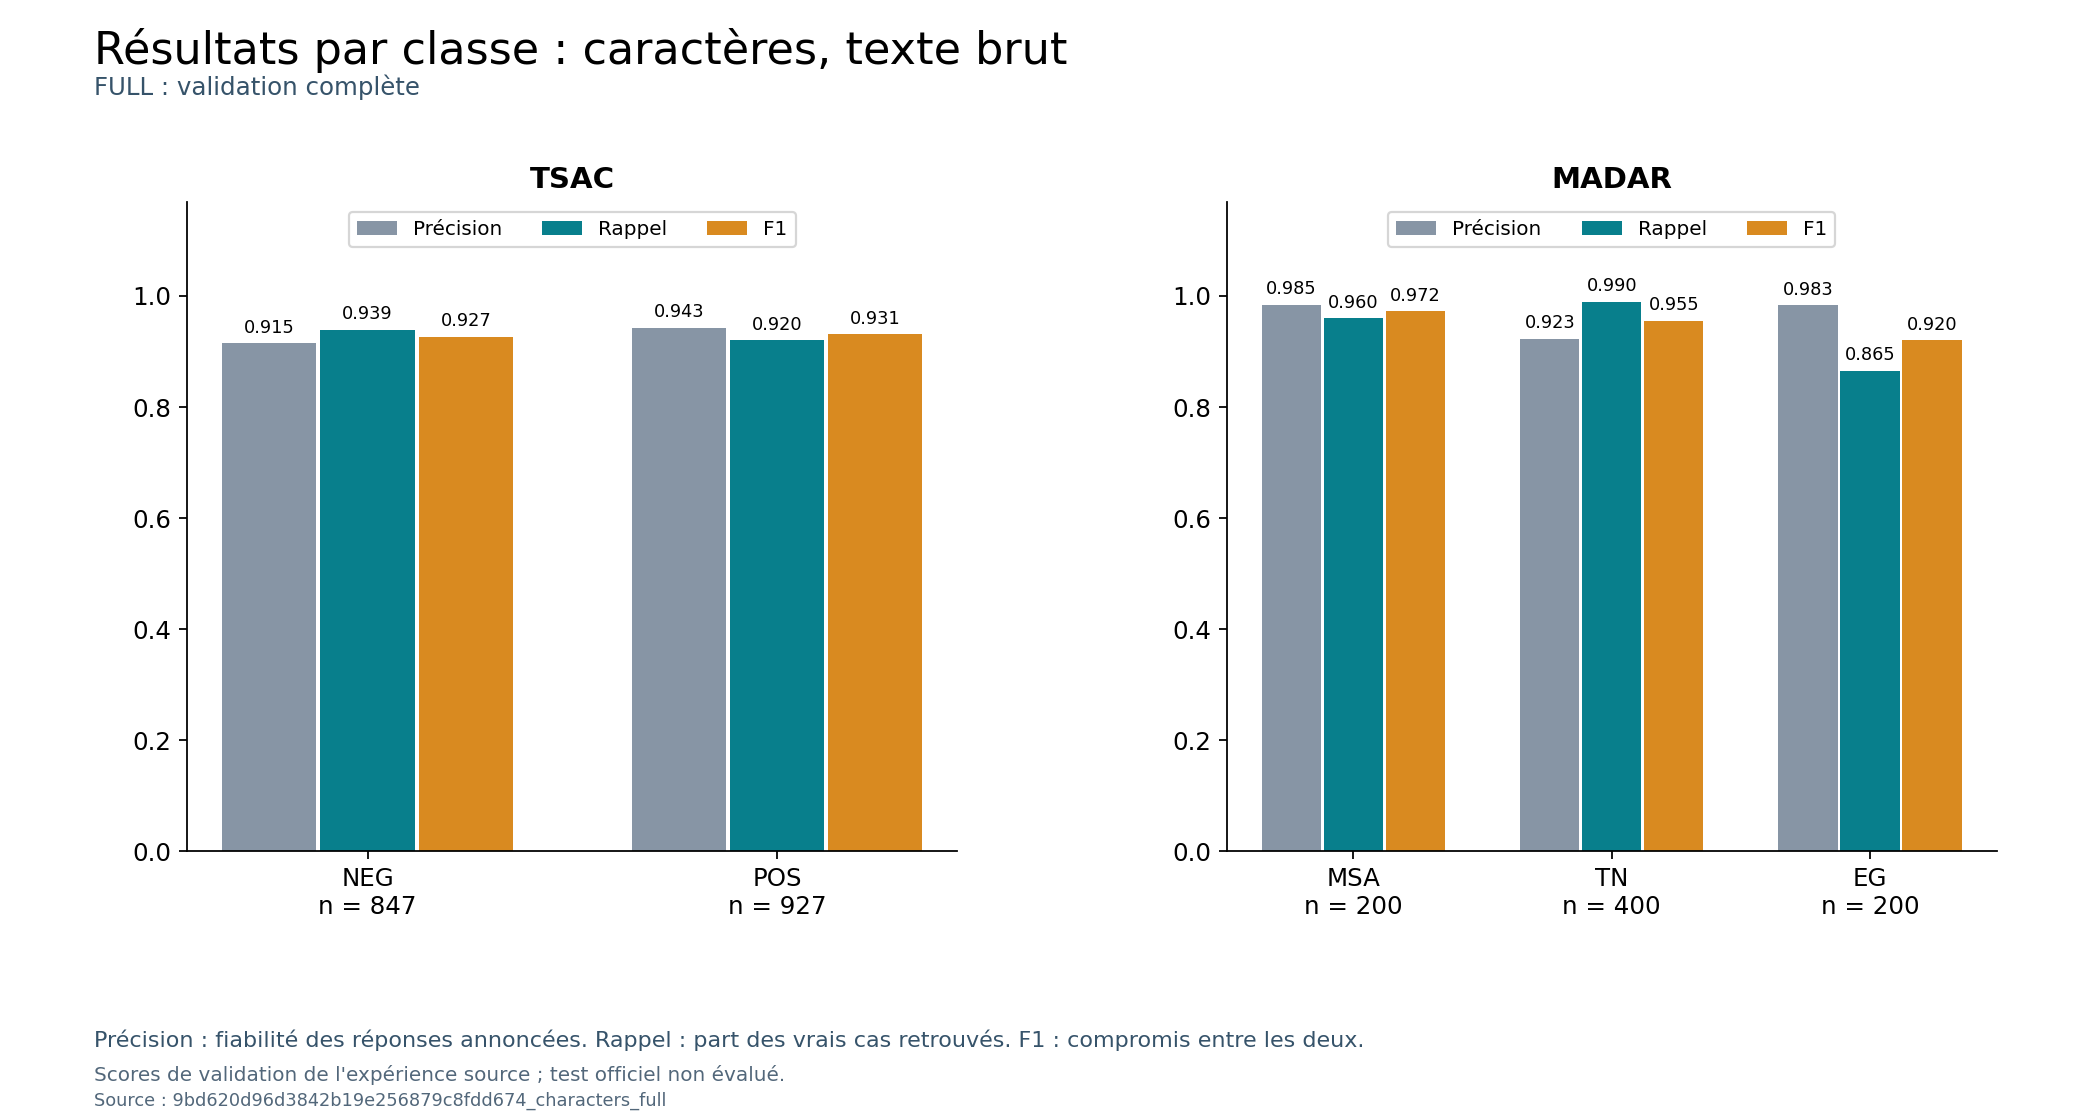

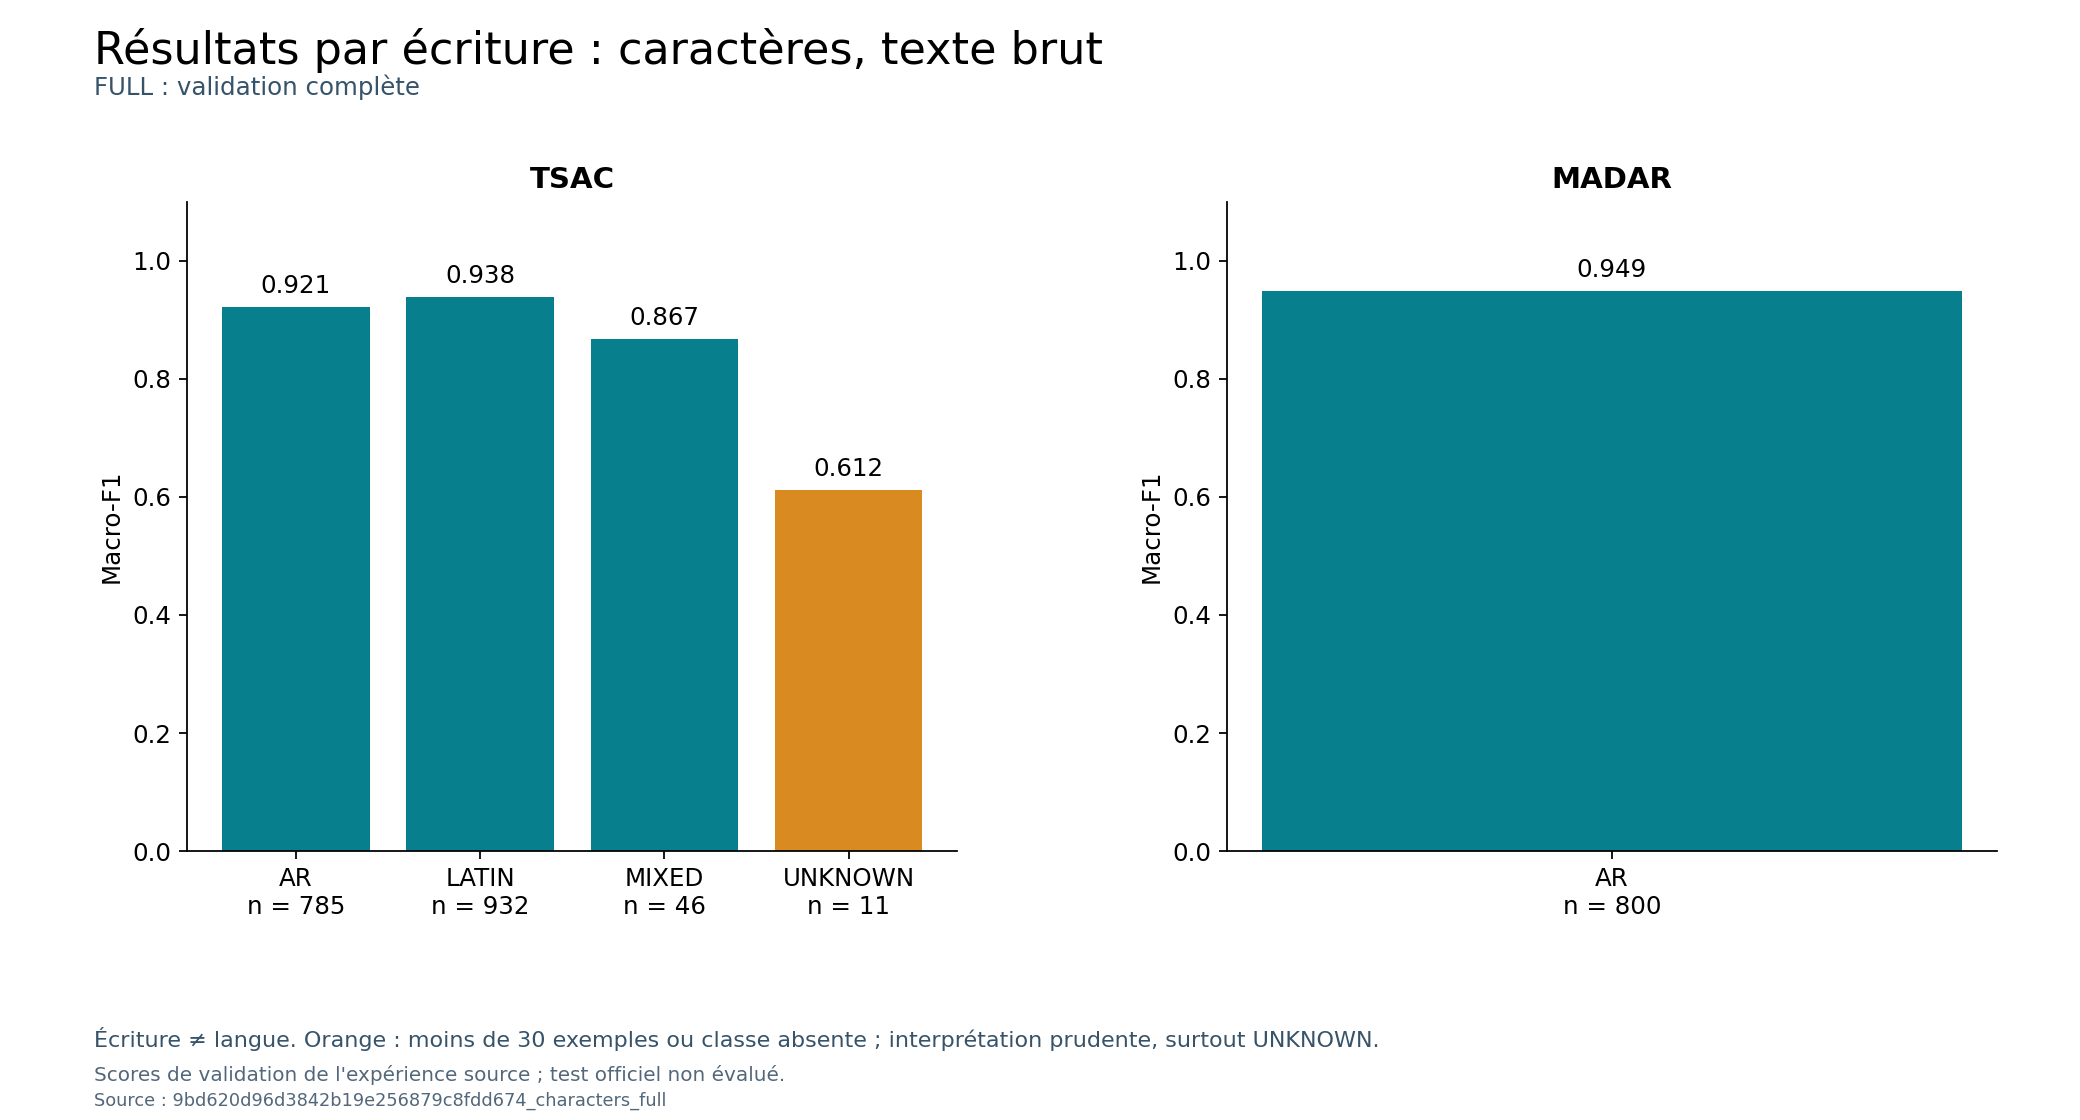

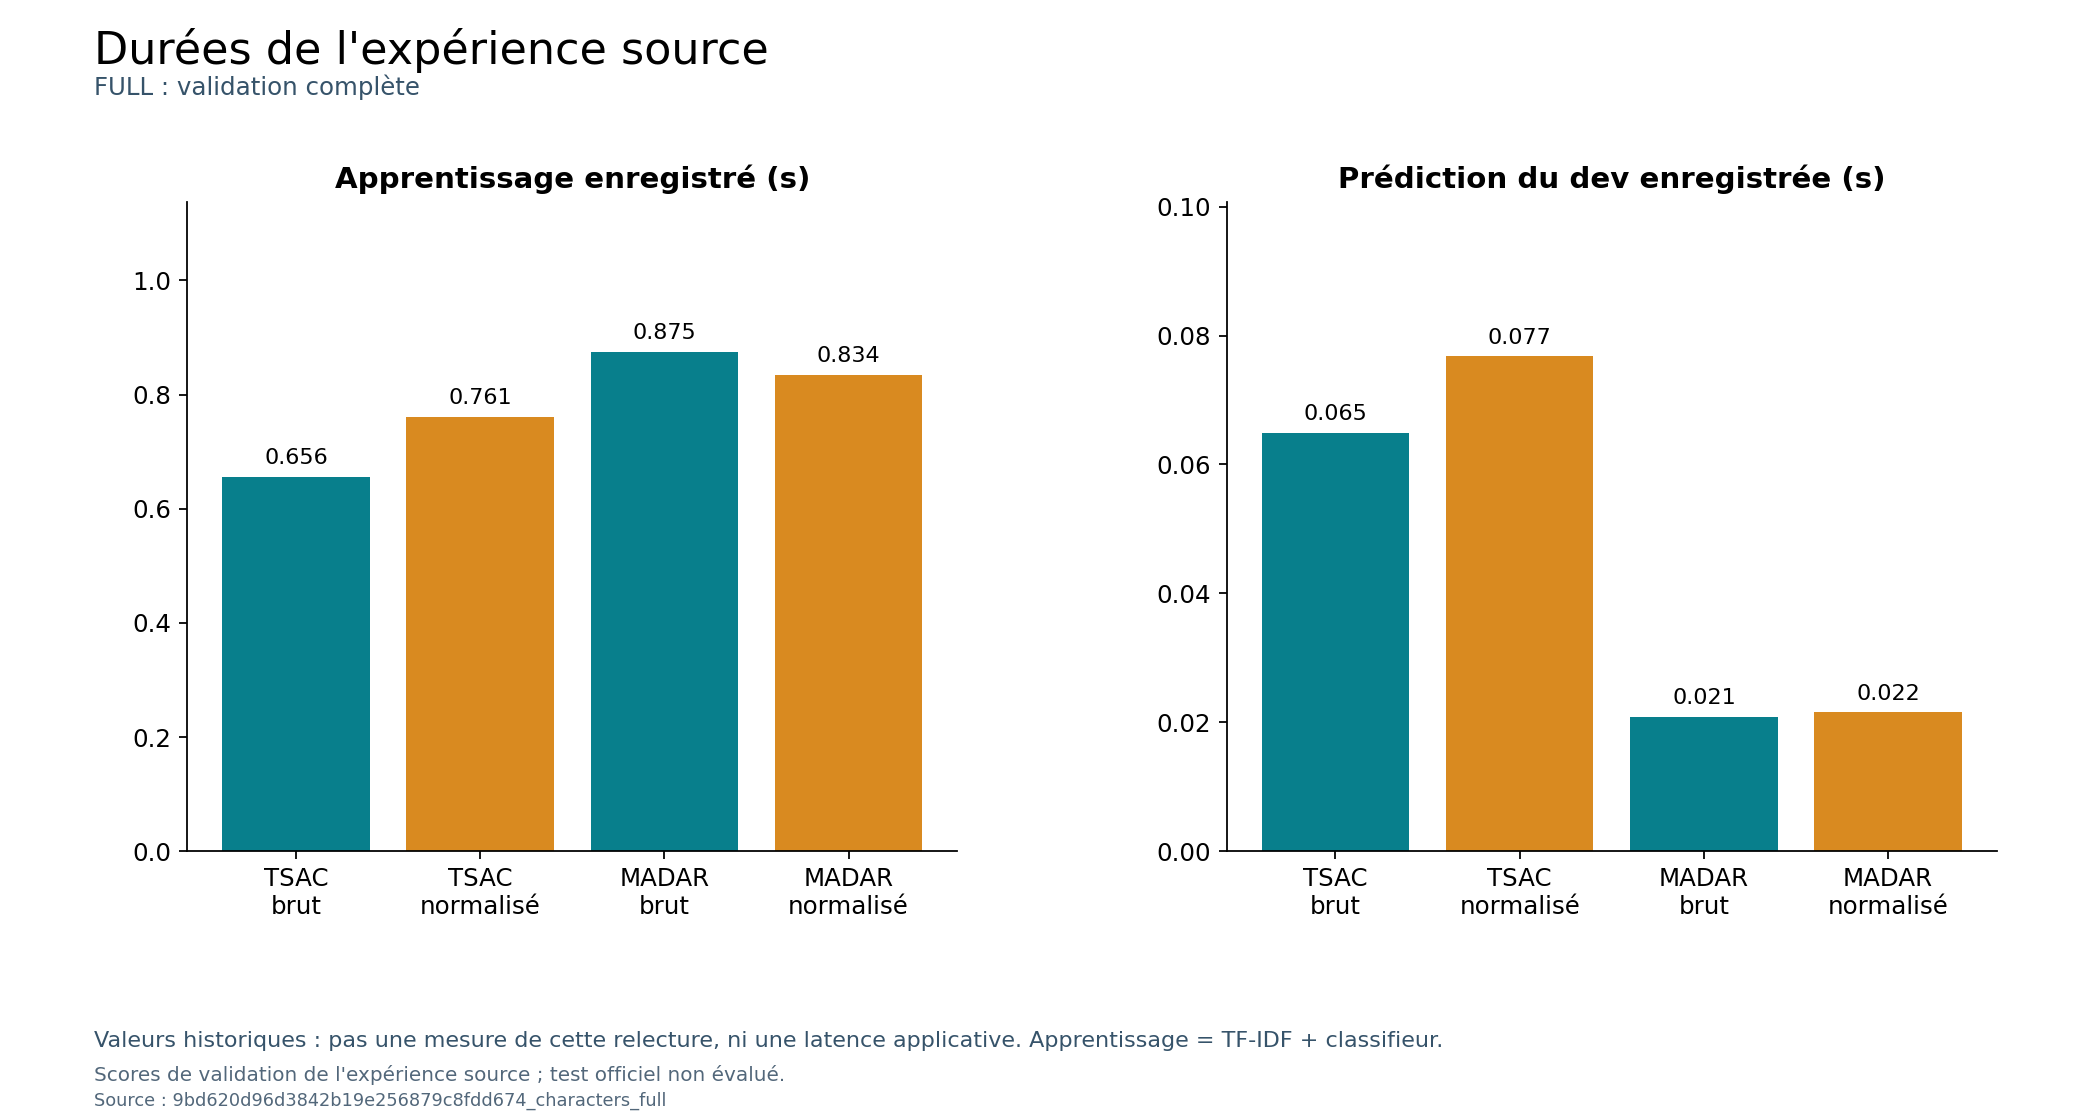

Terminé — FULL — six résultats vérifiés, six PNG enregistrés.
Dossier des PNG : /Users/elghoth/Desktop/NLP Project/outputs/baselines/notebooks/9bd620d96d3842b19e256879c8fdd674_characters_full/figures


In [4]:
if figure_report is not None:
    from IPython.display import display, Image
    for filename in figure_report['images']:
        display(Image(filename=str(Path(figure_report['directory']) / filename)))
    print('Terminé —', final_run['mode'].upper(), '— six résultats vérifiés, six PNG enregistrés.')
    print('Dossier des PNG :', figure_report['directory'])


## Interprétation

- **Scores globaux** : macro-F1 et accuracy de la majorité, du TF-IDF brut et normalisé ; ce sont des méthodes, pas des époques. Les scores portent sur le dev.
- **Matrices** : lignes = labels réels, colonnes = prédictions. La diagonale compte les bonnes réponses.
- **Classes** : précision, rappel et F1 par catégorie, avec effectifs.
- **Écritures** : AR/LATIN/MIXED/UNKNOWN désignent les alphabets présents, pas une langue. Les petits sous-ensembles sont signalés.
- **Durées** : celles de l'entraînement source qui vient d'être exécuté, pas une latence applicative.

Les futures expériences neuronales demanderont leur propre historique par époque ; celui-ci n'existe pas dans les fichiers des modèles classiques. Le notebook n'automatise pas les lexiques et augmentations, qui gardent leurs scripts dédiés.

**L04/L07/L11/L12 restent partiels** : références restantes, trois graines finales, bootstrap, test officiel et cloud demeurent à réaliser. Consigner chaque entraînement significatif dans `EXPERIMENTS.md`. Ne pas diffuser les sauvegardes contenant le vocabulaire appris ou charger un joblib non fiable.
